In [ ]:
import time

def timer(func):
    def wrapper():
        start = time.time()

        func()

        end = time.time()
        print(end - start)

    return wrapper


@timer
def test():
    time.sleep(1)


test()

2.0007166862487793


# ML1. Введение в машинное обучение

Анализ данных объявлений RentHop и построение моделей для прогнозирования цены аренды.

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import sklearn
try:
    import lightgbm
except (ImportError, OSError) as error:
    lightgbm = None
    print(f"lightgbm недоступен в текущем окружении: {error}")
import scipy
import statsmodels
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

lightgbm недоступен в текущем окружении: No module named 'lightgbm'


## 1. Введение

### 1.1. Пять примеров применения машинного обучения

1. Фильтрация спама в электронной почте. Модель автоматически отделяет нежелательные письма и экономит время пользователя.
2. Прогноз потребления электроэнергии. Прогноз помогает поставщику заранее планировать нагрузку и снижать затраты.
3. Обнаружение заболевания по медицинскому снимку. Модель помогает врачу быстрее заметить подозрительные признаки.
4. Сегментация покупателей по поведению. Группы клиентов позволяют делать более подходящие предложения.
5. Поиск товаров, которые часто покупают вместе. Ассоциативные правила помогают формировать рекомендации и комплекты товаров.

### 1.2. Классы задач

Для задач из таблицы во введении:

1. Цена дома — обучение с учителем, регрессия.
2. Возврат кредита — обучение с учителем, бинарная классификация.
3. Время, когда пациенту нужно принять лекарство, — обучение с учителем, регрессия, если прогнозируется число часов до приёма.
4. Выбор лекарства — обучение с учителем, многоклассовая классификация; целевая переменная — название лекарства.
5. Участие клиента в акции или покупка товара из акции — обучение с учителем, бинарная классификация. Для поиска групп клиентов можно использовать кластеризацию, а для поиска совместных покупок — ассоциативные правила.
6. Наличие дефекта — обучение с учителем, бинарная классификация.
7. Количество продаж или прибыль при размещении товаров — обучение с учителем, регрессия.
8. Откроет ли пользователь ссылку — обучение с учителем, бинарная классификация. Многоклассовая классификация по страницам неудобна из-за слишком большого количества классов.
9. Сегментация покупателей — обучение без учителя, кластеризация. Снижение размерности можно использовать для визуализации сегментов.
10. Обнаружение аномального трафика — обучение без учителя, поиск аномалий. При наличии размеченных примеров неисправностей задачу можно сформулировать как бинарную классификацию.

Для приведённых пяти примеров: 1 — бинарная классификация; 2 — регрессия; 3 — бинарная классификация; 4 — кластеризация; 5 — поиск ассоциативных правил.

### 1.3. Многоклассовая и многометочная классификация

В многоклассовой классификации каждому объекту назначается ровно один класс из нескольких взаимоисключающих классов. Например, фрукт может быть яблоком, грушей или бананом. В многометочной классификации одному объекту можно одновременно назначить несколько независимых меток. Например, документ может относиться одновременно к темам «финансы» и «образование».

### 1.4. Прогнозирование цены

Прогнозирование цены дома — задача регрессии, потому что целевая переменная принимает числовые значения на непрерывной шкале. Регрессию можно свести к классификации, разбив диапазон цен на интервалы и назначив каждому интервалу отдельный класс. При этом точное числовое значение заменяется категорией, поэтому часть информации теряется.

## 2. Введение в анализ данных

In [3]:
project_root = Path.cwd().resolve()
if not (project_root / "datasets" / "train.json").exists():
    project_root = project_root.parent

data_path = project_root / "datasets" / "train.json"
data = pd.read_json(data_path)
data.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,medium
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,low


### 2.1. Размер данных

In [4]:
print(f"Размер данных: {data.shape}")

Размер данных: (49352, 15)


В наборе данных 49 352 строки и 15 столбцов.

### 2.2. Столбцы и целевая переменная

In [5]:
print(data.columns.tolist())

['bathrooms', 'bedrooms', 'building_id', 'created', 'description', 'display_address', 'features', 'latitude', 'listing_id', 'longitude', 'manager_id', 'photos', 'price', 'street_address', 'interest_level']


В рамках этого проекта целевая переменная — `price`. Столбец `interest_level`, являвшийся целью исходного соревнования Kaggle, здесь используется как признак.

### 2.3. Быстрый анализ данных

In [6]:
data.info()

<class 'pandas.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  str    
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  str    
 14  interest_level   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


In [ ]:
data.describe(include="all").T

In [ ]:
data.select_dtypes(include=np.number).corr()

,bathrooms,bedrooms,latitude,listing_id,longitude,price
bathrooms,1.000000,0.533446,-0.009657,0.000776,0.010393,0.069661
bedrooms,0.533446,1.000000,-0.004745,0.011968,0.006892,0.051788
latitude,-0.009657,-0.004745,1.000000,0.001712,-0.966807,-0.000707
listing_id,0.000776,0.011968,0.001712,1.000000,-0.000907,0.008090
longitude,0.010393,0.006892,-0.966807,-0.000907,1.000000,-0.000087
price,0.069661,0.051788,-0.000707,0.008090,-0.000087,1.000000


In [ ]:
missing_values = data.isna().sum()
print(missing_values)
print(f"Пустых столбцов: {(missing_values == len(data)).sum()}")

bathrooms          0
bedrooms           0
building_id        0
created            0
description        0
display_address    0
features           0
latitude           0
listing_id         0
longitude          0
manager_id         0
photos             0
price              0
street_address     0
interest_level     0
dtype: int64
Пустых столбцов: 0


`info()` показывает типы данных и количество непустых значений, `describe()` — основные описательные статистики, а `corr()` — линейные корреляции числовых столбцов. Пропущенных значений и полностью пустых столбцов нет.

### 2.4. Рабочий набор столбцов

In [ ]:
model_data = data[["bathrooms", "bedrooms", "interest_level", "price"]].copy()
model_data.head()

,bathrooms,bedrooms,interest_level,price
4,1.0,1,medium,2400
6,1.0,2,low,3800
9,1.0,2,medium,3495
10,1.5,3,medium,3000
15,1.0,0,low,2795


## 3. Статистический анализ данных

Среднее — сумма значений, делённая на их количество. Медиана — центральное значение упорядоченного ряда. Мода — наиболее частое значение. Дисперсия — средний квадрат отклонения от среднего, стандартное отклонение — квадратный корень из дисперсии. Выброс — наблюдение, заметно отличающееся от основной массы данных. Процентиль задаёт значение, ниже которого находится указанная доля наблюдений. Доверительный интервал задаёт диапазон правдоподобных значений оцениваемого параметра.

### 3.1. Анализ целевой переменной

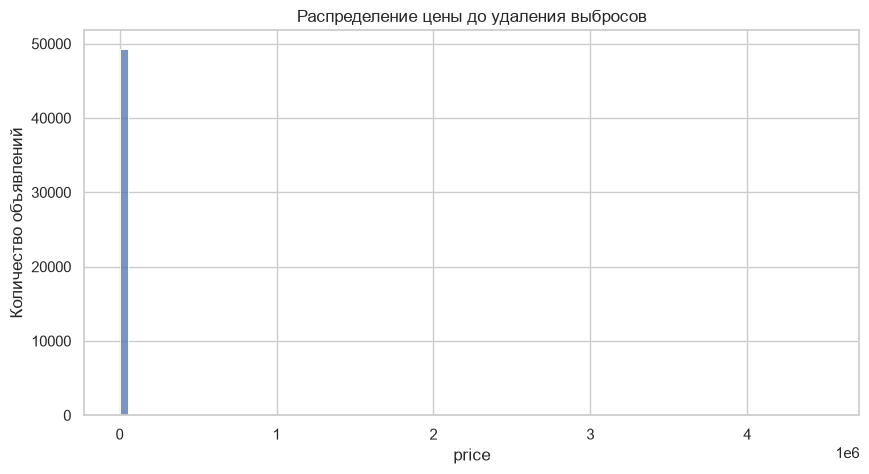

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(model_data["price"], bins=80)
plt.title("Распределение цены до удаления выбросов")
plt.xlabel("price")
plt.ylabel("Количество объявлений")
plt.show()

Из-за нескольких очень больших значений основная часть распределения сжата около нуля. По такой гистограмме нельзя хорошо рассмотреть типичные цены; необходимо исследовать выбросы.

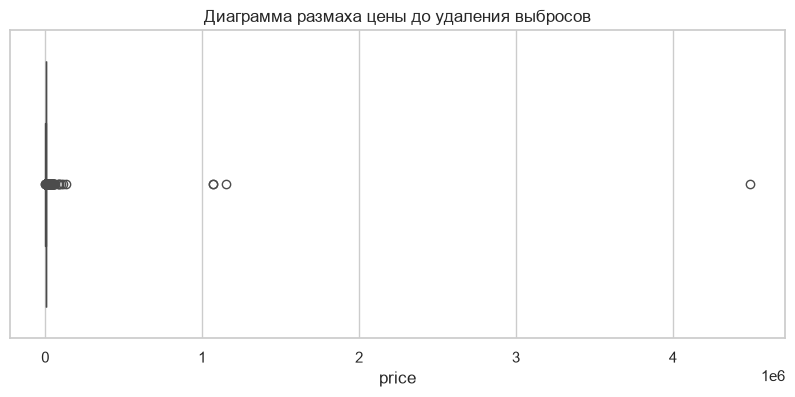

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=model_data["price"])
plt.title("Диаграмма размаха цены до удаления выбросов")
plt.xlabel("price")
plt.show()

Диаграмма размаха подтверждает наличие выбросов: некоторые цены значительно превышают основную массу значений.

In [ ]:
percentile_01 = model_data["price"].quantile(0.01)
percentile_99 = model_data["price"].quantile(0.99)
print(f"1-й процентиль: {percentile_01}")
print(f"99-й процентиль: {percentile_99}")

percentile_data = model_data[
    model_data["price"].between(percentile_01, percentile_99)
].copy()
model_data = model_data[
    (model_data["price"] > percentile_01)
    & (model_data["price"] < percentile_99)
].copy()
print(f"Размер после удаления выбросов: {model_data.shape}")

1-й процентиль: 1475.0
99-й процентиль: 13000.0
Размер после удаления выбросов: (48343, 4)


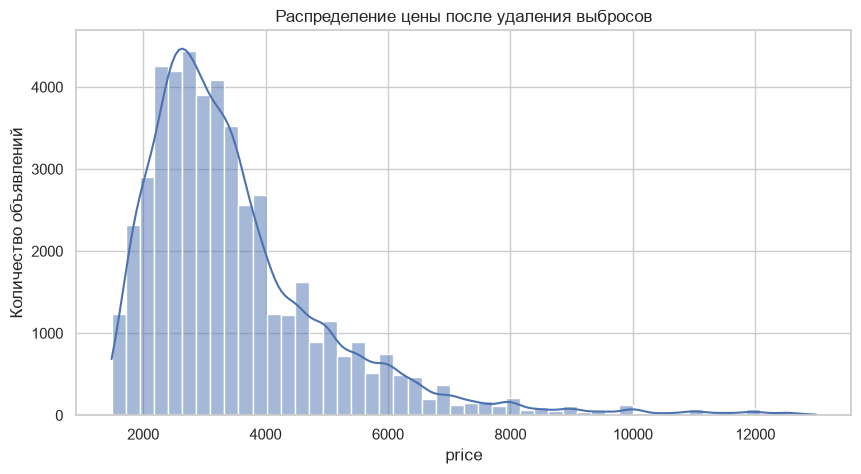

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(model_data["price"], bins=50, kde=True)
plt.title("Распределение цены после удаления выбросов")
plt.xlabel("price")
plt.ylabel("Количество объявлений")
plt.show()

После удаления наблюдений за пределами 1-го и 99-го процентилей распределение типичных цен видно значительно лучше. Оно имеет правую асимметрию: большинство объявлений находится в нижней части диапазона, а частота уменьшается при росте цены.

### 3.2. Анализ признаков

In [ ]:
print(f"Тип interest_level: {percentile_data['interest_level'].dtype}")
print(percentile_data["interest_level"].value_counts())

Тип interest_level: str
interest_level
low       33697
medium    11116
high       3566
Name: count, dtype: int64


`interest_level` имеет тип `object` и содержит три значения: `low`, `medium`, `high`. Они обозначают низкий, средний и высокий уровень интереса соответственно.

In [ ]:
interest_mapping = {"low": 0, "medium": 1, "high": 2}
model_data["interest_level"] = model_data["interest_level"].map(interest_mapping)
model_data["interest_level"].value_counts().sort_index()

interest_level
0    33672
1    11114
2     3557
Name: count, dtype: int64

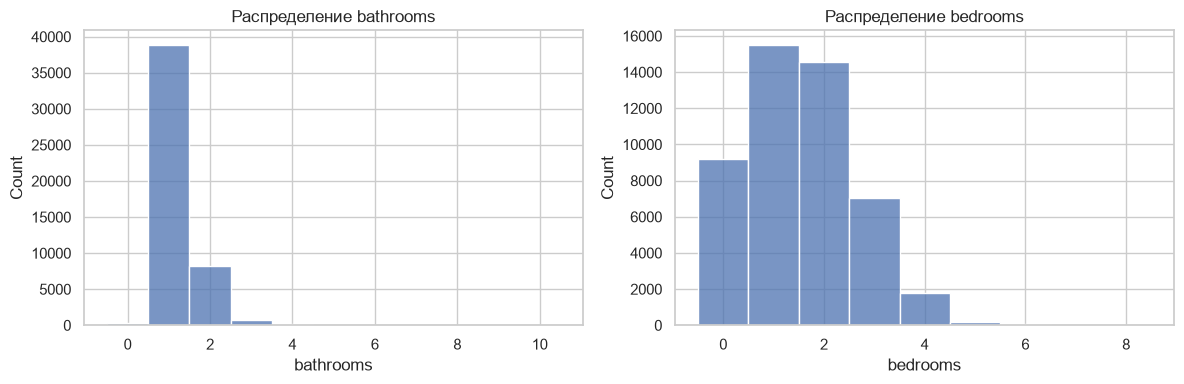

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(model_data["bathrooms"], discrete=True, ax=axes[0])
axes[0].set_title("Распределение bathrooms")
axes[0].set_xlabel("bathrooms")
sns.histplot(model_data["bedrooms"], discrete=True, ax=axes[1])
axes[1].set_title("Распределение bedrooms")
axes[1].set_xlabel("bedrooms")
plt.tight_layout()
plt.show()

Большинство объявлений содержит от 1 до 2 ванных комнат и от 0 до 3 спален. Редкие большие значения встречаются, но отдельных экстремальных выбросов, подобных выбросам цены, у этих признаков нет.

### 3.3. Комплексный анализ

,bathrooms,bedrooms,interest_level,price
bathrooms,1.000000,0.517200,-0.062819,0.670808
bedrooms,0.517200,1.000000,0.051282,0.547310
interest_level,-0.062819,0.051282,1.000000,-0.199652
price,0.670808,0.547310,-0.199652,1.000000


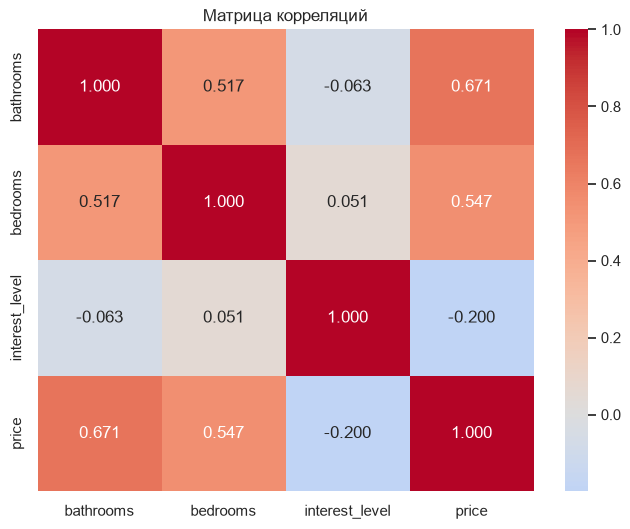

In [ ]:
correlation = model_data.corr()
display(correlation)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Матрица корреляций")
plt.show()

Самая сильная положительная корреляция с `price` наблюдается у `bathrooms` (около 0.67), затем у `bedrooms` (около 0.55). У `interest_level` слабая отрицательная корреляция с ценой (около −0.20).

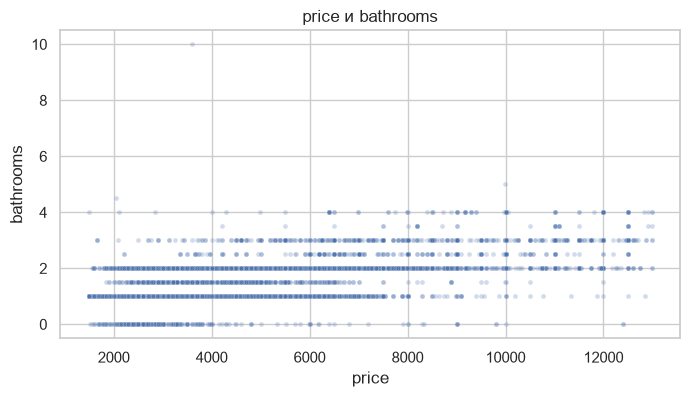

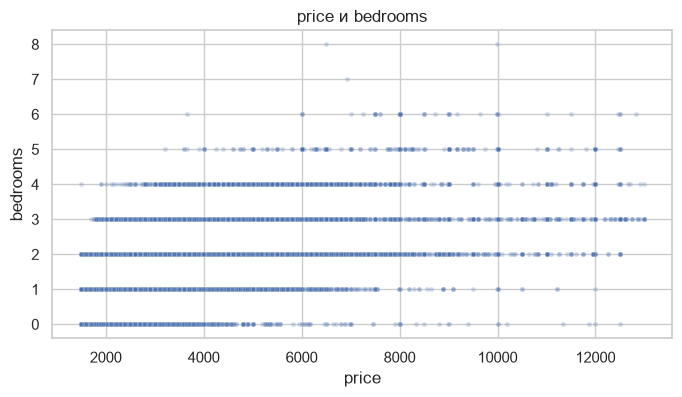

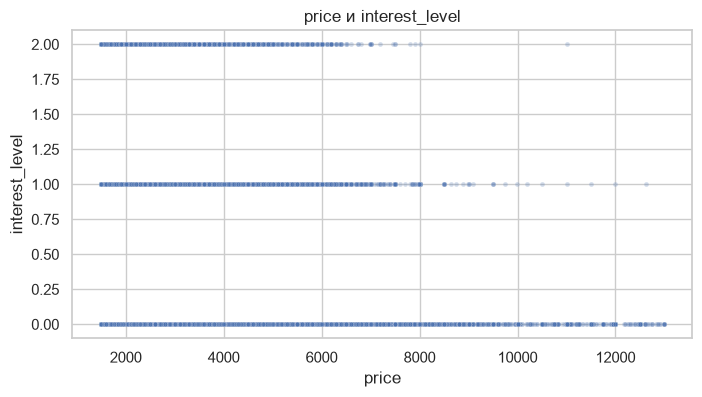

In [ ]:
for feature in ["bathrooms", "bedrooms", "interest_level"]:
    plt.figure(figsize=(8, 4))
    sns.scatterplot(data=model_data, x="price", y=feature, alpha=0.25, s=12)
    plt.title(f"price и {feature}")
    plt.xlabel("price")
    plt.ylabel(feature)
    plt.show()

Диаграммы рассеяния подтверждают положительную связь цены с количеством ванных комнат и спален. Для `interest_level` заметна слабая обратная связь: более высокий интерес чаще встречается у менее дорогих объявлений.

## 4. Создание признаков

In [ ]:
model_data["bathrooms_squared"] = model_data["bathrooms"] ** 2
model_data["bedrooms_squared"] = model_data["bedrooms"] ** 2
model_data["interest_level_squared"] = model_data["interest_level"] ** 2

squared_correlation = model_data.corr()
display(squared_correlation)

,bathrooms,bedrooms,interest_level,price,bathrooms_squared,bedrooms_squared,interest_level_squared
bathrooms,1.000000,0.517200,-0.062819,0.670808,0.955906,0.548426,-0.058710
bedrooms,0.517200,1.000000,0.051282,0.547310,0.478497,0.928282,0.040125
interest_level,-0.062819,0.051282,1.000000,-0.199652,-0.067757,0.047048,0.943959
price,0.670808,0.547310,-0.199652,1.000000,0.646949,0.544612,-0.182283
bathrooms_squared,0.955906,0.478497,-0.067757,0.646949,1.000000,0.521951,-0.061563
bedrooms_squared,0.548426,0.928282,0.047048,0.544612,0.521951,1.000000,0.036408
interest_level_squared,-0.058710,0.040125,0.943959,-0.182283,-0.061563,0.036408,1.000000


Квадрат `bathrooms` коррелирует с целью слабее исходного признака (`0.647` против `0.671`). Квадрат `bedrooms` имеет примерно такую же корреляцию (`0.545` против `0.547`), а квадрат `interest_level` — немного более слабую по модулю отрицательную корреляцию (`−0.182` против `−0.200`). Новые признаки не стали сильнее связаны с целью.

Для обучения используются исходные признаки `bathrooms`, `bedrooms` и закодированный `interest_level`. Описание `PolynomialFeatures`: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html

### 4.1. Обучающая и тестовая выборки

In [ ]:
base_features = ["bathrooms", "bedrooms", "interest_level"]
train_data, test_data = train_test_split(
    model_data[base_features + ["price"]],
    test_size=0.25,
    random_state=1,
)

X_train = train_data[base_features]
X_test = test_data[base_features]
y_train = train_data["price"]
y_test = test_data["price"]

print(f"Обучающая выборка: {train_data.shape}")
print(f"Тестовая выборка: {test_data.shape}")

Обучающая выборка: (36257, 4)
Тестовая выборка: (12086, 4)


In [ ]:
polynomial = PolynomialFeatures(degree=10)
X_train_polynomial = polynomial.fit_transform(X_train)
X_test_polynomial = polynomial.transform(X_test)

print(f"Признаков до преобразования: {X_train.shape[1]}")
print(f"Признаков после PolynomialFeatures: {X_train_polynomial.shape[1]}")

Признаков до преобразования: 3
Признаков после PolynomialFeatures: 286


## 5. Обучение моделей

In [ ]:
result_MAE = pd.DataFrame(columns=["model", "train", "test"])
result_RMSE = pd.DataFrame(columns=["model", "train", "test"])

def add_results(model_name, train_target, train_prediction, test_target, test_prediction):
    global result_MAE, result_RMSE
    mae_row = pd.DataFrame([{
        "model": model_name,
        "train": mean_absolute_error(train_target, train_prediction),
        "test": mean_absolute_error(test_target, test_prediction),
    }])
    rmse_row = pd.DataFrame([{
        "model": model_name,
        "train": np.sqrt(mean_squared_error(train_target, train_prediction)),
        "test": np.sqrt(mean_squared_error(test_target, test_prediction)),
    }])
    result_MAE = pd.concat([result_MAE, mae_row], ignore_index=True)
    result_RMSE = pd.concat([result_RMSE, rmse_row], ignore_index=True)

### 5.1. Линейная регрессия

In [ ]:
linear_regression = LinearRegression()
linear_regression.fit(X_train_polynomial, y_train)

train_data["linear_regression"] = linear_regression.predict(X_train_polynomial)
test_data["linear_regression"] = linear_regression.predict(X_test_polynomial)

add_results(
    "linear_regression",
    y_train,
    train_data["linear_regression"],
    y_test,
    test_data["linear_regression"],
)

### 5.2. Дерево решений

In [ ]:
decision_tree = DecisionTreeRegressor(random_state=21)
decision_tree.fit(X_train, y_train)

train_data["decision_tree"] = decision_tree.predict(X_train)
test_data["decision_tree"] = decision_tree.predict(X_test)

add_results(
    "decision_tree",
    y_train,
    train_data["decision_tree"],
    y_test,
    test_data["decision_tree"],
)

### 5.3. Наивные модели

In [ ]:
train_mean = y_train.mean()
train_median = y_train.median()

train_data["naive_mean"] = train_mean
test_data["naive_mean"] = train_mean
train_data["naive_median"] = train_median
test_data["naive_median"] = train_median

add_results("naive_mean", y_train, train_data["naive_mean"], y_test, test_data["naive_mean"])
add_results("naive_median", y_train, train_data["naive_median"], y_test, test_data["naive_median"])

### 5.4. Сравнение результатов

In [ ]:
print("MAE")
display(result_MAE)
print("RMSE")
display(result_RMSE)

MAE


,model,train,test
0,linear_regression,828.633388,873.670128
1,decision_tree,718.335591,726.523218
2,naive_mean,1124.770343,1156.35067
3,naive_median,1073.794274,1107.499917


RMSE


,model,train,test
0,linear_regression,1178.465899,2574.018616
1,decision_tree,1025.356121,1036.059208
2,naive_mean,1572.875395,1623.259518
3,naive_median,1617.851788,1672.633572


Лучшая модель — `decision_tree`: у неё наименьшие значения MAE и RMSE на тестовой выборке. Линейная регрессия с полиномиальными признаками степени 10 нестабильна на тестовых данных, а обе наивные модели уступают дереву решений.